# Assignment 1: Data Profiling (EDA)
### Topic: Apartment Rental Prices in Kuala Lumpur and Selangor

**Group members:**

| Name | Matric No. |
|---|---|
| MUHAMMAD AIMAN FAIQ BIN EMRAN | A211494 |
| MUHAMMAD FIRDAUS BIN SUHAIMI | A211437 |
| MUHAMMAD IZZAT AMIR BIN MOHD ZAKI | A211680 |
| MANVEER SINGH A/L RAVINDER SINGH | A211153 |

## 1. Scenario

Many students and fresh graduates move to KL or Selangor for study or work, and the first problem they face is finding a place to rent. A lot of them don't know what a normal rent is for a certain area, so they can easily pay too much.

For this assignment we imagine that our **student union wants to make a simple "fair rent guide"**. The guide would tell students the normal rent for a unit based on area, type of property, size and furnishing.

To make this guide we need rental data. Before we can use it, we have to check whether the data is clean and can be trusted. That is the focus of this notebook.

**Questions we want the data to answer (after cleaning):**
1. What is the normal monthly rent in different areas and for different property types?
2. How much do size and furnishing affect the rent?


## 2. Data Source

- **Dataset name:** Rental Pricing Dataset, Malaysia
- **Link:** https://www.kaggle.com/datasets/ariewijaya/rent-pricing-kuala-lumpur-malaysi
- **Where the data comes from:** The dataset owner scraped rental ads for apartments and condos in KL and Selangor from **mudah.my**.
- **How we got it:** We downloaded the CSV file from Kaggle (need to have free account) and put it in the files.
- **Size:** around 10,000 rows
- **Date we downloaded it:** 31/10/2026
- **Licence:**  https://creativecommons.org/licenses/by/4.0/

We chose this dataset because it is real data scraped from a website, so it is not clean. When we first opened it in Excel we could already see problems, for example rent written as "RM 1 500 per month" instead of a number.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [ ]:
# load the data
# change the file name here if your file is named differently
file_name = "mudah-apartment-kl-selangor.csv"
df = pd.read_csv(file_name)

print("Number of rows and columns:", df.shape)
df.head()

Number of rows and columns: (19991, 14)


,ads_id,prop_name,completion_year,monthly_rent,location,property_type,rooms,parking,bathroom,size,furnished,facilities,additional_facilities,region
0,100323185,The Hipster @ Taman Desa,2022.0,RM 4 200 per month,Kuala Lumpur - Taman Desa,Condominium,5,2.0,6.0,1842 sq.ft.,Fully Furnished,"Minimart, Gymnasium, Security, Playground, Swi...","Air-Cond, Cooking Allowed, Washing Machine",Kuala Lumpur
1,100203973,Segar Courts,NaN,RM 2 300 per month,Kuala Lumpur - Cheras,Condominium,3,1.0,2.0,1170 sq.ft.,Partially Furnished,"Playground, Parking, Barbeque area, Security, ...","Air-Cond, Cooking Allowed, Near KTM/LRT",Kuala Lumpur
2,100323128,Pangsapuri Teratak Muhibbah 2,NaN,RM 1 000 per month,Kuala Lumpur - Taman Desa,Apartment,3,NaN,2.0,650 sq.ft.,Fully Furnished,"Minimart, Jogging Track, Lift, Swimming Pool",NaN,Kuala Lumpur
3,100191767,Sentul Point Suite Apartment,2020.0,RM 1 700 per month,Kuala Lumpur - Sentul,Apartment,2,1.0,2.0,743 sq.ft.,Partially Furnished,"Parking, Playground, Swimming Pool, Squash Cou...","Cooking Allowed, Near KTM/LRT, Washing Machine",Kuala Lumpur
4,97022692,Arte Mont Kiara,NaN,RM 1 299 per month,Kuala Lumpur - Mont Kiara,Service Residence,1,1.0,1.0,494 sq.ft.,Not Furnished,"Parking, Security, Lift, Swimming Pool, Playgr...",Air-Cond,Kuala Lumpur


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19991 entries, 0 to 19990
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ads_id                 19991 non-null  int64  
 1   prop_name              19043 non-null  object 
 2   completion_year        10806 non-null  float64
 3   monthly_rent           19989 non-null  object 
 4   location               19991 non-null  object 
 5   property_type          19991 non-null  object 
 6   rooms                  19985 non-null  object 
 7   parking                14289 non-null  float64
 8   bathroom               19985 non-null  float64
 9   size                   19991 non-null  object 
 10  furnished              19986 non-null  object 
 11  facilities             17782 non-null  object 
 12  additional_facilities  14043 non-null  object 
 13  region                 19991 non-null  object 
dtypes: float64(3), int64(1), object(10)
memory usage: 2.1+

**What we noticed first:**
- `monthly_rent` and `size` should be numbers, but they are stored as text (object) because they contain "RM", "per month" and "sq.ft.".
- `rooms` is also text, which is strange because the number of rooms should be a number.
- `location` has two pieces of information in one column (state and area), e.g. "Kuala Lumpur - Cheras".
- Some columns have fewer non-null values than the total rows, so there is missing data.

Before we change anything we make a copy of the data, so we can always compare with the original.

In [ ]:
df_clean = df.copy()

## 3. Data Profiling and Cleaning

### 3.1 Wrong data types and inconsistent formats

We fix the format problems first, because we need rent and size as numbers before we can check for missing values or outliers.

**Monthly rent**

In [ ]:
# look at some examples first
print(df_clean["monthly_rent"].head(10))

0    RM 4 200 per month
1    RM 2 300 per month
2    RM 1 000 per month
3    RM 1 700 per month
4    RM 1 299 per month
5    RM 1 500 per month
6    RM 2 900 per month
7    RM 1 550 per month
8    RM 1 400 per month
9    RM 1 350 per month
Name: monthly_rent, dtype: object


In [ ]:
# remove "RM", "per month" and the spaces, then change to number
df_clean["monthly_rent"] = df_clean["monthly_rent"].str.replace("RM", "")
df_clean["monthly_rent"] = df_clean["monthly_rent"].str.replace("per month", "")
df_clean["monthly_rent"] = df_clean["monthly_rent"].str.replace(" ", "")
df_clean["monthly_rent"] = pd.to_numeric(df_clean["monthly_rent"], errors="coerce")

print(df_clean["monthly_rent"].head())
print("Rent values that could not be converted:", df_clean["monthly_rent"].isnull().sum())

0    4200.0
1    2300.0
2    1000.0
3    1700.0
4    1299.0
Name: monthly_rent, dtype: float64
Rent values that could not be converted: 2


**Size**

In [ ]:
print(df_clean["size"].head(10))

df_clean["size"] = df_clean["size"].str.replace("sq.ft.", "")
df_clean["size"] = df_clean["size"].str.replace(" ", "")
df_clean["size"] = pd.to_numeric(df_clean["size"], errors="coerce")

print(df_clean["size"].head())

0    1842 sq.ft.
1    1170 sq.ft.
2     650 sq.ft.
3     743 sq.ft.
4     494 sq.ft.
5     884 sq.ft.
6     982 sq.ft.
7     700 sq.ft.
8     750 sq.ft.
9     862 sq.ft.
Name: size, dtype: object
0    1842
1    1170
2     650
3     743
4     494
Name: size, dtype: int64


**Rooms**

`rooms` should be a number, so we check why it is stored as text.

In [ ]:
print(df_clean["rooms"].value_counts(dropna=False))

rooms
3.0             6460
3               6320
2               1805
1.0             1527
2.0             1489
4                915
1                867
4.0              474
5                 54
5.0               38
6                 19
NaN                6
7                  6
6.0                4
More than 10       2
7.0                2
9                  1
9.0                1
10.0               1
Name: count, dtype: int64


In [ ]:
# some values are text like "More than 10", these can't become a number so they become NaN
df_clean["rooms"] = pd.to_numeric(df_clean["rooms"], errors="coerce")
df_clean["bathroom"] = pd.to_numeric(df_clean["bathroom"], errors="coerce")
df_clean["parking"] = pd.to_numeric(df_clean["parking"], errors="coerce")

**Location**

We split location into two columns: `state` and `area`.

In [ ]:
df_clean[["state", "area"]] = df_clean["location"].str.split(" - ", n=1, expand=True)
df_clean["state"] = df_clean["state"].str.strip()
df_clean["area"] = df_clean["area"].str.strip()

print(df_clean["state"].value_counts())
print("\nNumber of different areas:", df_clean["area"].nunique())

state
Selangor        10000
Kuala Lumpur     9991
Name: count, dtype: int64

Number of different areas: 129


**Categories (property type and furnished)**

We check the labels to see if anything is spelled differently or has very few rows.

In [ ]:
print(df_clean["property_type"].value_counts())
print()
print(df_clean["furnished"].value_counts(dropna=False))

property_type
Condominium                                           8448
Service Residence                                     5310
Apartment                                             5258
Flat                                                   581
Studio                                                 189
Others                                                  89
Duplex                                                  76
Townhouse Condo                                         35
Condo / Services residence / Penthouse / Townhouse       1
Residential                                              1
Bungalow House                                           1
Houses                                                   1
Soho                                                     1
Name: count, dtype: int64

furnished
Fully Furnished        8462
Partially Furnished    8004
Not Furnished          3520
NaN                       5
Name: count, dtype: int64


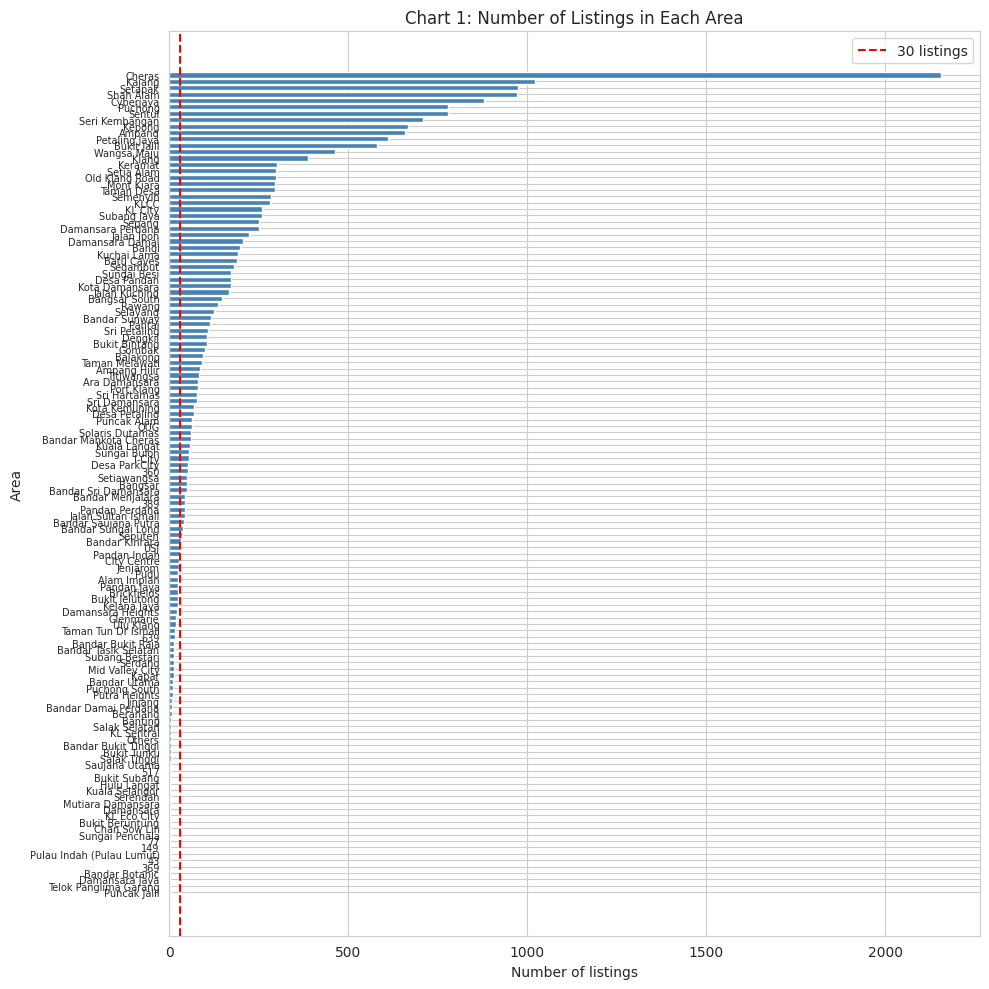

Areas with less than 30 listings: 55


In [ ]:
# Chart 1: number of listings in each area
area_counts = df_clean["area"].value_counts()

plt.figure(figsize=(10, 10))
plt.barh(area_counts.index, area_counts.values, color="steelblue")
plt.axvline(30, color="red", linestyle="--", label="30 listings")
plt.gca().invert_yaxis()
plt.title("Chart 1: Number of Listings in Each Area")
plt.xlabel("Number of listings")
plt.ylabel("Area")
plt.yticks(fontsize=7)
plt.legend()
plt.tight_layout()
plt.show()

print("Areas with less than 30 listings:", (area_counts < 30).sum())

**What we found and what we did:**
- `furnished` is fine: there are only 3 options (Fully, Partially, Not Furnished).
- `property_type` has a few types with very few listings (e.g. Studio, Duplex, Townhouse Condo, Others). We group the small ones into **"Others"** because we can't calculate a reliable average rent from only 20 or 30 listings.
- Chart 1 shows that some areas have very few listings. For the rent guide we will only show areas with at least 30 listings. We still keep the small areas in the data, but we group them as **"Other KL"** and **"Other Selangor"** in a new column.

In [ ]:
# group rare property types
type_counts = df_clean["property_type"].value_counts()
rare_types = type_counts[type_counts < 50].index
print("Rare property types:", list(rare_types))

df_clean["property_group"] = df_clean["property_type"]
df_clean.loc[df_clean["property_type"].isin(rare_types), "property_group"] = "Others"

# group rare areas
rare_areas = area_counts[area_counts < 30].index
df_clean["area_group"] = df_clean["area"]
df_clean.loc[df_clean["area"].isin(rare_areas), "area_group"] = "Other " + df_clean["state"]

print(df_clean["property_group"].value_counts())

Rare property types: ['Townhouse Condo', 'Condo / Services residence / Penthouse / Townhouse', 'Residential', 'Bungalow House', 'Houses', 'Soho']
property_group
Condominium          8448
Service Residence    5310
Apartment            5258
Flat                  581
Studio                189
Others                129
Duplex                 76
Name: count, dtype: int64


### 3.2 Missing values

First we check for **hidden missing values**. These are values like "-" or empty text that pandas doesn't count as missing.

In [ ]:
for col in df_clean.columns:
    if df_clean[col].dtype == "object" or str(df_clean[col].dtype) in ["str", "string"]:
        count = (df_clean[col].astype(str).str.strip().isin(["-", "", "N/A", "None"])).sum()
        if count > 0:
            print(col, ":", count, "hidden missing values")

In [ ]:
# change them to real NaN
df_clean = df_clean.replace(["-", "", "N/A", "None"], np.nan)

In [ ]:
missing = df_clean.isnull().sum()
missing_percent = (missing / len(df_clean) * 100).round(1)
missing_table = pd.DataFrame({"missing": missing, "percent": missing_percent})
missing_table = missing_table[missing_table["missing"] > 0].sort_values("percent", ascending=False)
missing_table

,missing,percent
completion_year,9185,45.9
additional_facilities,5948,29.8
parking,5702,28.5
facilities,2209,11.0
prop_name,948,4.7
rooms,8,0.0
monthly_rent,2,0.0
furnished,5,0.0
bathroom,6,0.0


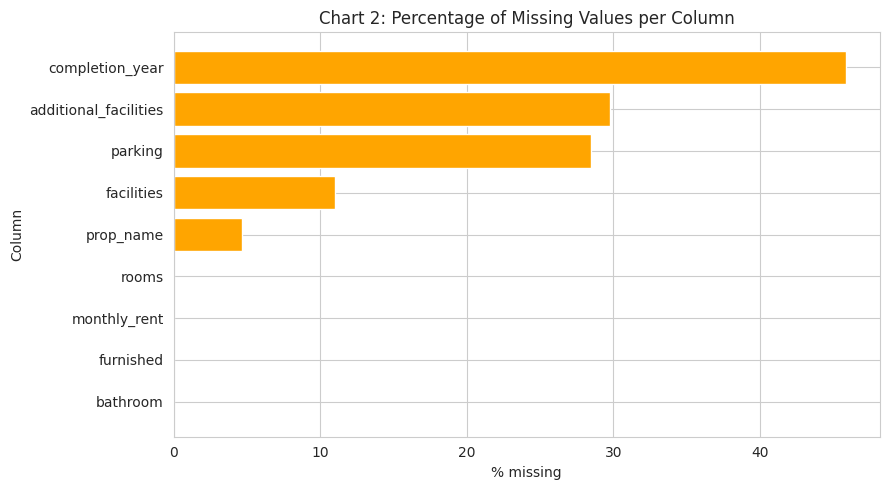

In [ ]:
# Chart 2: percentage of missing values in each column
plt.figure(figsize=(9, 5))
plt.barh(missing_table.index, missing_table["percent"], color="orange")
plt.gca().invert_yaxis()
plt.title("Chart 2: Percentage of Missing Values per Column")
plt.xlabel("% missing")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

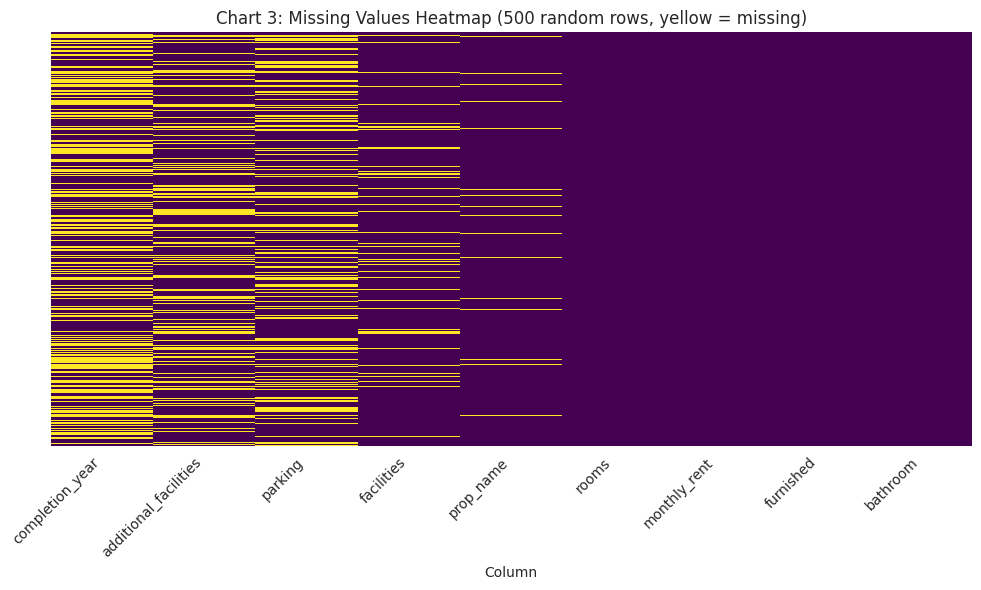

In [ ]:
# Chart 3: heatmap to see the pattern of missing values (yellow = missing)
plt.figure(figsize=(10, 6))
sns.heatmap(df_clean[missing_table.index].sample(500, random_state=1).isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Chart 3: Missing Values Heatmap (500 random rows, yellow = missing)")
plt.xlabel("Column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

From the charts, `completion_year`, `parking` and `additional_facilities` have the most missing values. `rooms`, `bathroom` and `furnished` only have a few.

Before deciding what to do, we want to know whether the missing values happen **randomly** or not. If they are not random, deleting or filling them could make our results biased. So we compare listings with and without missing parking.

In [ ]:
df_clean["parking_missing"] = df_clean["parking"].isnull()

# median rent and size for listings with and without parking info
print(df_clean.groupby("parking_missing")[["monthly_rent", "size"]].median())

                 monthly_rent   size
parking_missing                     
False                  1500.0  910.0
True                   1250.0  811.0


In [ ]:
# % of listings with missing parking for each property type
print((pd.crosstab(df_clean["property_type"], df_clean["parking_missing"], normalize="index") * 100).round(1))

parking_missing                                     False  True 
property_type                                                   
Apartment                                            62.6   37.4
Bungalow House                                        0.0  100.0
Condo / Services residence / Penthouse / Townhouse    0.0  100.0
Condominium                                          80.7   19.3
Duplex                                               50.0   50.0
Flat                                                 20.3   79.7
Houses                                              100.0    0.0
Others                                               40.4   59.6
Residential                                           0.0  100.0
Service Residence                                    72.9   27.1
Soho                                                100.0    0.0
Studio                                               54.0   46.0
Townhouse Condo                                      57.1   42.9


In [ ]:
df_clean["completion_year_missing"] = df_clean["completion_year"].isnull()
print(df_clean.groupby("completion_year_missing")[["monthly_rent", "size"]].median())

                         monthly_rent   size
completion_year_missing                     
False                          1600.0  903.0
True                           1204.0  850.0


**What we found:** Missing parking is **not random**. It happens much more often for apartments and flats than for condos. This makes sense because cheaper apartments often don't have a fixed parking lot, so the owner just leaves the field empty.

**What we decided to do:**

- **`completion_year` (~40% missing):** We **leave it empty** and add a column that marks which rows are missing. Too much data is missing to guess, and we don't need the building year for our main questions.
- **`parking` (~25% missing):** We **leave it empty**, with a marker column. We don't fill it with 0 because empty could mean "no parking" or just "not stated". We also don't fill it with the average, because the missing values are not random.
- **`facilities` and `additional_facilities`:** We fill them with **"Not stated"**. The owner just didn't tick anything, so we can't say the unit has no facilities.
- **`prop_name` (~5% missing):** We **leave it empty**. We only use it to check for duplicates.
- **`rooms`, `bathroom`, `furnished`, `monthly_rent` (very few missing):** We **delete these rows**. Very few rows are affected, and these are important columns for the rent guide.

In [ ]:
df_clean["facilities"] = df_clean["facilities"].fillna("Not stated")
df_clean["additional_facilities"] = df_clean["additional_facilities"].fillna("Not stated")

rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["monthly_rent", "rooms", "bathroom", "furnished"])
print("Rows deleted:", rows_before - len(df_clean))
print("Rows left:", len(df_clean))

Rows deleted: 10
Rows left: 19981


### 3.3 Duplicates

In [ ]:
print("Fully duplicated rows:", df_clean.duplicated().sum())
print("Duplicated ads_id:", df_clean["ads_id"].duplicated().sum())

Fully duplicated rows: 8
Duplicated ads_id: 13


In [ ]:
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.drop_duplicates(subset="ads_id")
print("Rows left:", len(df_clean))

Rows left: 19968


On mudah.my, agents often post the **same unit again** with a new ad so it shows up at the top of the search. These reposts have a different `ads_id`, so the checks above won't catch them. We check for listings with the same building name, area, rent, size, rooms, bathrooms and furnishing.

In [ ]:
same_unit_cols = ["prop_name", "area", "monthly_rent", "size", "rooms", "bathroom", "furnished"]
repost = df_clean.duplicated(subset=same_unit_cols, keep=False) & df_clean["prop_name"].notnull()
print("Listings that look like reposts:", repost.sum())

df_clean[repost].sort_values(same_unit_cols).head(10)

Listings that look like reposts: 7740


,ads_id,prop_name,completion_year,monthly_rent,location,property_type,rooms,parking,bathroom,size,furnished,facilities,additional_facilities,region,state,area,property_group,area_group,parking_missing,completion_year_missing
14184,100739791,1 Harmonis,NaN,1600.0,Selangor - Gombak,Condominium,3.0,1.0,2.0,1100,Partially Furnished,"Playground, Gymnasium, Jogging Track, Swimming...",Cooking Allowed,Selangor,Selangor,Gombak,Condominium,Gombak,False,True
14900,100714342,1 Harmonis,NaN,1600.0,Selangor - Gombak,Condominium,3.0,NaN,2.0,1100,Partially Furnished,"Gymnasium, Jogging Track, Tennis Court, Securi...","Internet, Near KTM/LRT, Cooking Allowed",Selangor,Selangor,Gombak,Condominium,Gombak,True,True
14252,100736631,1 Harmonis,NaN,1800.0,Selangor - Gombak,Condominium,3.0,1.0,2.0,1338,Partially Furnished,"Playground, Gymnasium, Jogging Track, Swimming...",Cooking Allowed,Selangor,Selangor,Gombak,Condominium,Gombak,False,True
14899,100714347,1 Harmonis,NaN,1800.0,Selangor - Gombak,Condominium,3.0,NaN,2.0,1338,Partially Furnished,"Gymnasium, Jogging Track, Tennis Court, Securi...","Internet, Cooking Allowed, Near KTM/LRT",Selangor,Selangor,Gombak,Condominium,Gombak,True,True
18458,100563316,1 Harmonis,NaN,1800.0,Selangor - Gombak,Condominium,3.0,1.0,2.0,1338,Partially Furnished,"Jogging Track, Playground, Tennis Court, Secur...","Air-Cond, Cooking Allowed, Near KTM/LRT, Washi...",Selangor,Selangor,Gombak,Condominium,Gombak,False,True
88,100320954,1 Petaling,2012.0,1100.0,Kuala Lumpur - Sungai Besi,Condominium,3.0,1.0,2.0,904,Partially Furnished,"Jogging Track, Swimming Pool, Playground, Secu...","Air-Cond, Cooking Allowed, Near KTM/LRT, Washi...",Kuala Lumpur,Kuala Lumpur,Sungai Besi,Condominium,Sungai Besi,False,False
4626,99870590,1 Petaling,2012.0,1100.0,Kuala Lumpur - Sungai Besi,Condominium,3.0,1.0,2.0,904,Partially Furnished,"Barbeque area, Security, Swimming Pool, Multip...","Air-Cond, Cooking Allowed, Near KTM/LRT, Washi...",Kuala Lumpur,Kuala Lumpur,Sungai Besi,Condominium,Sungai Besi,False,False
9904,99612231,1 Petaling,2012.0,1100.0,Kuala Lumpur - Sungai Besi,Condominium,3.0,1.0,2.0,904,Partially Furnished,"Swimming Pool, Security, Jogging Track, Multip...","Air-Cond, Cooking Allowed, Near KTM/LRT, Washi...",Kuala Lumpur,Kuala Lumpur,Sungai Besi,Condominium,Sungai Besi,False,False
1806,100251204,1 Petaling,2012.0,1200.0,Kuala Lumpur - Sungai Besi,Condominium,3.0,1.0,2.0,900,Partially Furnished,"Barbeque area, Multipurpose hall, Security, Pl...","Near KTM/LRT, Cooking Allowed, Air-Cond",Kuala Lumpur,Kuala Lumpur,Sungai Besi,Condominium,Sungai Besi,False,False
2767,99927139,1 Petaling,2012.0,1200.0,Kuala Lumpur - Sungai Besi,Condominium,3.0,1.0,2.0,900,Partially Furnished,"Barbeque area, Multipurpose hall, Security, Pl...","Near KTM/LRT, Cooking Allowed, Air-Cond",Kuala Lumpur,Kuala Lumpur,Sungai Besi,Condominium,Sungai Besi,False,False


In [ ]:
# keep only one of each repost (keep the newest ad, which has the bigger ads_id)
df_clean = df_clean.sort_values("ads_id")
rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=same_unit_cols, keep="last")
print("Reposts removed:", rows_before - len(df_clean))
print("Rows left:", len(df_clean))

Reposts removed: 5260
Rows left: 14708


**Why we removed them:** If one unit is posted 5 times, its rent would be counted 5 times when we calculate the normal rent for that area, and the result becomes biased. It is possible that a few of these are actually different units on different floors with the same size and price, but we think most of them are reposts. We mention this in our limitations.

### 3.4 Invalid values

We check for values that are impossible, or that don't make sense for an apartment rental in KL or Selangor.

In [ ]:
print(df_clean[["monthly_rent", "size", "rooms", "bathroom", "parking", "completion_year"]].describe().round(1))

       monthly_rent        size    rooms  bathroom  parking  completion_year
count       14708.0     14708.0  14708.0   14708.0  10354.0           7542.0
mean         2430.5      7726.2      2.7       1.9      1.4           2014.4
std         25725.7    824554.3      0.8       0.6      0.6              6.9
min            70.0         1.0      1.0       1.0      1.0           1977.0
25%          1100.0       750.0      2.0       2.0      1.0           2011.0
50%          1400.0       893.0      3.0       2.0      1.0           2016.0
75%          1800.0      1050.0      3.0       2.0      2.0           2019.0
max       2400000.0  99999999.0     10.0       8.0     10.0           2025.0


In [ ]:
print("Rent below RM100:", (df_clean["monthly_rent"] < 100).sum())
print("Size below 100 sq ft:", (df_clean["size"] < 100).sum())
print("Size above 20,000 sq ft:", (df_clean["size"] > 20000).sum())
print("Rooms = 0:", (df_clean["rooms"] == 0).sum())
print("Bathroom = 0:", (df_clean["bathroom"] == 0).sum())
print("Completion year after 2026:", (df_clean["completion_year"] > 2026).sum())
print("Completion year before 1960:", (df_clean["completion_year"] < 1960).sum())

Rent below RM100: 4
Size below 100 sq ft: 28
Size above 20,000 sq ft: 2
Rooms = 0: 0
Bathroom = 0: 0
Completion year after 2026: 0
Completion year before 1960: 0


**What we found:**
- Some listings have a rent of **RM 0** or a very small amount. Nobody rents out a whole apartment for less than RM 100, so these are probably mistakes or placeholder values.
- Some sizes are impossible, e.g. 1 sq ft or **100,000,000 sq ft**. That is bigger than a whole town.
- Some completion years are in the future. A year 1 to 3 years after the data was collected can be an under-construction project, but a year much later than that is a mistake.

**What we did:**
- **Rent below RM 100: delete the row.** Rent is the main thing we study, so a row with a wrong rent is useless.
- **Wrong size: change only the size to NaN.** The rent and other information in the row are still fine, so we don't want to delete the whole row.
- **Rooms or bathrooms = 0: change to NaN.**
- **Completion year after 2026 or before 1960: change to NaN.**

In [ ]:
df_clean = df_clean[df_clean["monthly_rent"] >= 100]

df_clean.loc[(df_clean["size"] < 100) | (df_clean["size"] > 20000), "size"] = np.nan
df_clean.loc[df_clean["rooms"] == 0, "rooms"] = np.nan
df_clean.loc[df_clean["bathroom"] == 0, "bathroom"] = np.nan
df_clean.loc[(df_clean["completion_year"] > 2026) | (df_clean["completion_year"] < 1960), "completion_year"] = np.nan

print("Rows left:", len(df_clean))

Rows left: 14704


### 3.5 Outliers

Now we look at extreme values in `monthly_rent`.

In [ ]:
print(df_clean["monthly_rent"].describe().round(0))
print("Skewness:", round(df_clean["monthly_rent"].skew(), 2))

count      14704.0
mean        2431.0
std        25729.0
min          100.0
25%         1100.0
50%         1400.0
75%         1800.0
max      2400000.0
Name: monthly_rent, dtype: float64
Skewness: 62.7


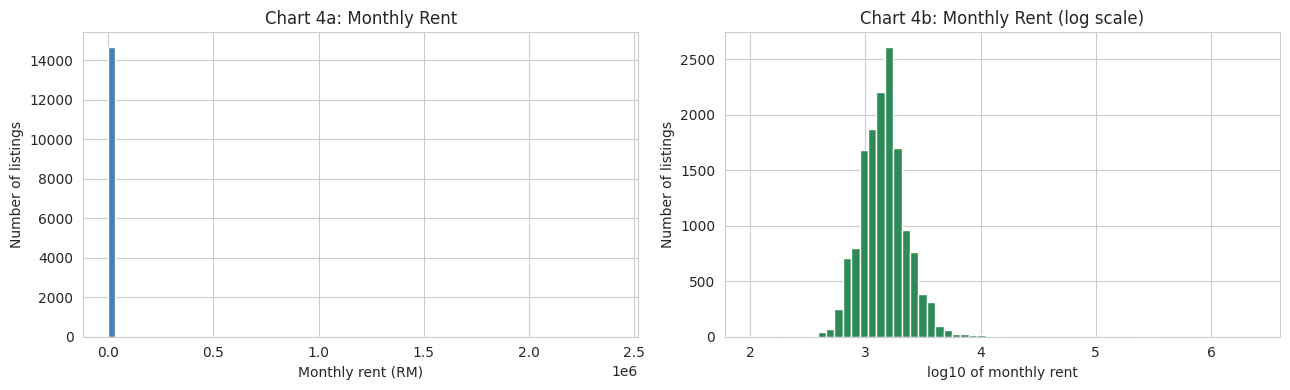

In [ ]:
# Chart 4: histogram of rent
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].hist(df_clean["monthly_rent"], bins=80, color="steelblue")
ax[0].set_title("Chart 4a: Monthly Rent")
ax[0].set_xlabel("Monthly rent (RM)")
ax[0].set_ylabel("Number of listings")

ax[1].hist(np.log10(df_clean["monthly_rent"]), bins=60, color="seagreen")
ax[1].set_title("Chart 4b: Monthly Rent (log scale)")
ax[1].set_xlabel("log10 of monthly rent")
ax[1].set_ylabel("Number of listings")

plt.tight_layout()
plt.show()

Chart 4a shows the rent is **very right-skewed**: most units are between RM 1,000 and RM 2,500, but a few are extremely high. After we take the log (Chart 4b), the shape looks closer to a normal bell curve.

We tried **two methods** to detect outliers and compare them.

In [ ]:
# Method 1: z-score
mean = df_clean["monthly_rent"].mean()
std = df_clean["monthly_rent"].std()
z = (df_clean["monthly_rent"] - mean) / std
print("Z-score method (|z| > 3):", (abs(z) > 3).sum(), "outliers")

# Method 2: IQR
Q1 = df_clean["monthly_rent"].quantile(0.25)
Q3 = df_clean["monthly_rent"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("IQR method:", ((df_clean["monthly_rent"] < lower) | (df_clean["monthly_rent"] > upper)).sum(), "outliers")
print("IQR upper limit: RM", round(upper))

Z-score method (|z| > 3): 30 outliers
IQR method: 985 outliers
IQR upper limit: RM 2850


**Comparing the two methods:**
- The **z-score** method doesn't work well here. It assumes the data is normally distributed, but our data is skewed. The very big values also push up the mean and standard deviation, so some outliers "hide" themselves.
- The **normal IQR** method flags too many listings. Its upper limit is only around RM 3,000+, so normal luxury condos (e.g. in Mont Kiara or KLCC) are counted as outliers even though their rent is real.

So we decided to use **IQR on log(rent), separately for each property type**. The log fixes the skew, and doing it per property type means we compare condos with condos and flats with flats. We use **3 × IQR** to catch only the really extreme values (probably typing mistakes, like an extra zero).

In [ ]:
df_clean["log_rent"] = np.log(df_clean["monthly_rent"])
df_clean["is_outlier"] = False

for ptype in df_clean["property_group"].unique():
    rows = df_clean["property_group"] == ptype
    q1 = df_clean.loc[rows, "log_rent"].quantile(0.25)
    q3 = df_clean.loc[rows, "log_rent"].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 3 * iqr
    high = q3 + 3 * iqr
    outlier = rows & ((df_clean["log_rent"] < low) | (df_clean["log_rent"] > high))
    df_clean.loc[outlier, "is_outlier"] = True
    print(f"{ptype}: normal range RM{np.exp(low):.0f} - RM{np.exp(high):.0f}, outliers = {outlier.sum()}")

print("\nTotal outliers:", df_clean["is_outlier"].sum())

Condominium: normal range RM357 - RM7283, outliers = 79
Service Residence: normal range RM312 - RM9521, outliers = 18
Apartment: normal range RM238 - RM4651, outliers = 18
Duplex: normal range RM560 - RM4749, outliers = 2
Others: normal range RM109 - RM17320, outliers = 0
Studio: normal range RM406 - RM3322, outliers = 2
Flat: normal range RM293 - RM2087, outliers = 5

Total outliers: 124


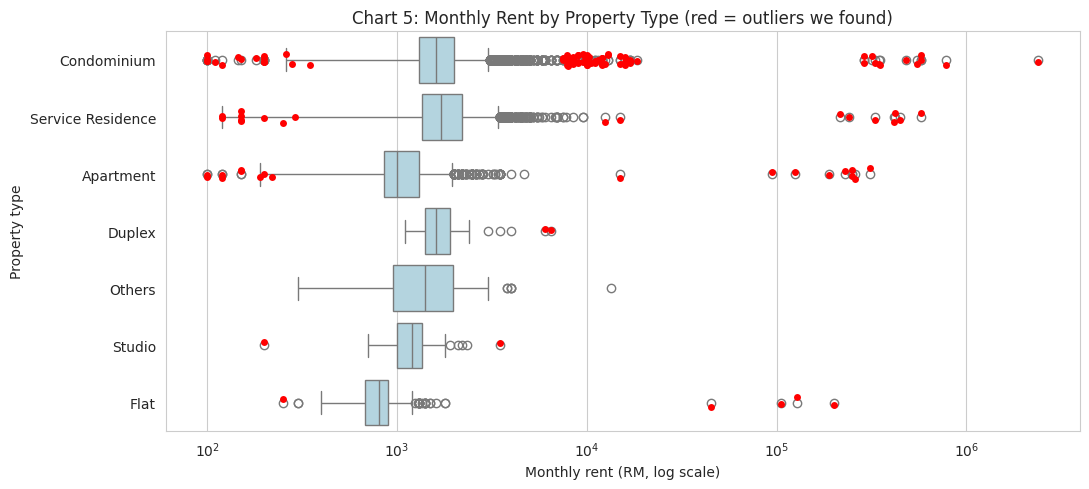

In [ ]:
# Chart 5: boxplot of rent by property type
plt.figure(figsize=(11, 5))
sns.boxplot(data=df_clean, x="monthly_rent", y="property_group", color="lightblue")
outliers = df_clean[df_clean["is_outlier"]]
sns.stripplot(data=outliers, x="monthly_rent", y="property_group", color="red", size=5)
plt.xscale("log")
plt.title("Chart 5: Monthly Rent by Property Type (red = outliers we found)")
plt.xlabel("Monthly rent (RM, log scale)")
plt.ylabel("Property type")
plt.tight_layout()
plt.show()

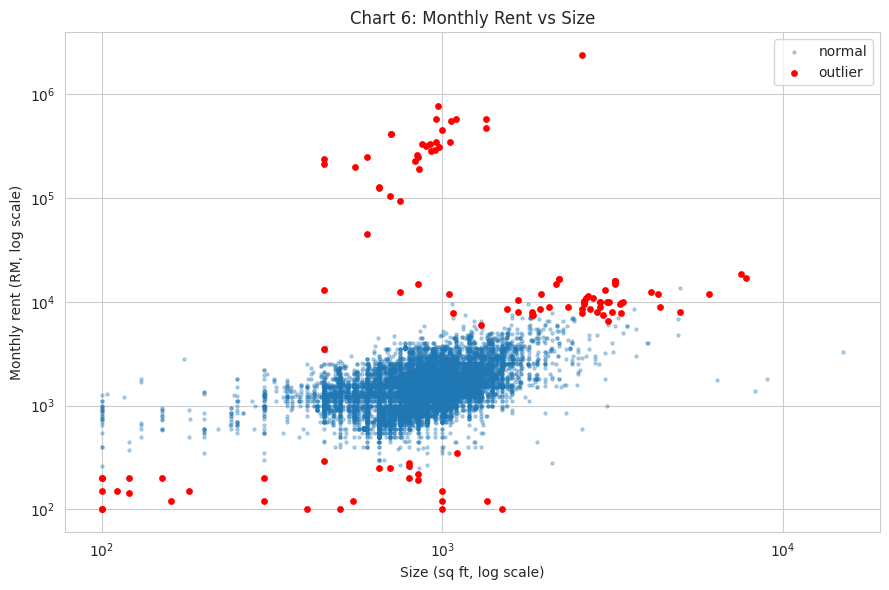

In [ ]:
# Chart 6: rent vs size, to see listings that don't follow the normal pattern
plt.figure(figsize=(9, 6))
normal = df_clean[~df_clean["is_outlier"]]
plt.scatter(normal["size"], normal["monthly_rent"], s=5, alpha=0.3, label="normal")
plt.scatter(outliers["size"], outliers["monthly_rent"], s=15, color="red", label="outlier")
plt.xscale("log")
plt.yscale("log")
plt.title("Chart 6: Monthly Rent vs Size")
plt.xlabel("Size (sq ft, log scale)")
plt.ylabel("Monthly rent (RM, log scale)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# look at the outliers
df_clean[df_clean["is_outlier"]][["prop_name", "area", "property_type", "size", "monthly_rent"]].sort_values("monthly_rent", ascending=False).head(10)

,prop_name,area,property_type,size,monthly_rent
4672,Sunway Vivaldi,Sri Hartamas,Condominium,2573.0,2400000.0
6367,NaN,Bukit Jalil,Condominium,971.0,780000.0
5705,United Point Residence @ North Kiara,Kepong,Service Residence,958.0,580000.0
8640,Parkhill Residence Bukit Jalil,Bukit Jalil,Condominium,1100.0,580000.0
2374,The Tamarind,Sentul,Condominium,1345.0,580000.0
8642,The Haute,Keramat,Condominium,1061.0,550000.0
17065,USJ One Avenue,Subang Jaya,Condominium,1346.0,480000.0
17988,Urban 360,Gombak,Service Residence,1001.0,450000.0
7336,The Elements,Ampang,Service Residence,705.0,419000.0
7369,The Elements,Ampang,Service Residence,705.0,418000.0


**What we decided:**
- The outliers we found are mostly **mistakes**: e.g. a small 500 sq ft apartment with a rent of tens of thousands of ringgit, which is probably a sale price typed in the wrong place or an extra zero. In Chart 6 you can see that these points are far away from the main group.
- We **remove these outliers** from the rent guide data, because they would push the average rent up a lot.
- We **keep the normal expensive units** (the grey dots in the boxplot that are not red). Expensive condos are real, and removing them would make KL look cheaper than it really is.
- For the guide we will use the **median** instead of the mean, because the median is not affected much by the few expensive units that are left.

In [ ]:
rows_before = len(df_clean)
df_clean = df_clean[df_clean["is_outlier"] == False]
df_clean = df_clean.drop(columns=["log_rent", "is_outlier"])
print("Outliers removed:", rows_before - len(df_clean))
print("Rows left:", len(df_clean))

Outliers removed: 124
Rows left: 14580


## 4. Checking if the groups are balanced

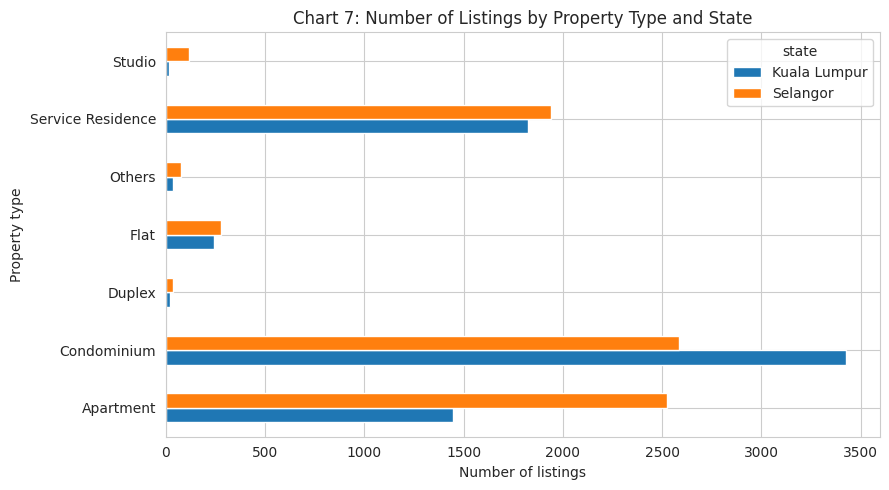

state
Selangor        0.52
Kuala Lumpur    0.48
Name: proportion, dtype: float64
furnished
Fully Furnished        0.41
Partially Furnished    0.40
Not Furnished          0.19
Name: proportion, dtype: float64


In [ ]:
# Chart 7: number of listings by property type and state
pd.crosstab(df_clean["property_group"], df_clean["state"]).plot(kind="barh", figsize=(9, 5))
plt.title("Chart 7: Number of Listings by Property Type and State")
plt.xlabel("Number of listings")
plt.ylabel("Property type")
plt.tight_layout()
plt.show()

print(df_clean["state"].value_counts(normalize=True).round(2))
print(df_clean["furnished"].value_counts(normalize=True).round(2))

The data is **not balanced**:
- Most listings are condominiums and serviced residences. Flats and the "Others" group are very small.
- There are more listings from KL than from Selangor.
- A few areas have a lot of listings, while many areas have fewer than 30 (Chart 1).

This means our rent guide will be more accurate for big areas and condos, and less accurate for small areas and flats.

## 5. PII and Bias Risks

### 5.1 PII (Personally Identifiable Information)

This dataset doesn't have obvious PII like names or IC numbers, but we still found some risks:
- **`ads_id`**: if you put this ID into mudah.my you can open the real ad, which shows the owner's or agent's **name and phone number**.
- **`prop_name`**: this is free text typed by the advertiser. Some people put their **phone number** or **unit number** in it.
- **Building + size + rent together** can point to one specific unit, and from that you could work out who owns it.

Under Malaysia's **PDPA 2010**, we should protect information that can identify a person.

In [ ]:
# search for phone numbers and unit numbers inside prop_name
phone_pattern = r"01\d[\s-]?\d{3,4}[\s-]?\d{4}"
unit_pattern = r"[A-Za-z]-\d{1,2}-\d{1,2}"

print("prop_name with phone number:", df_clean["prop_name"].str.contains(phone_pattern, na=False).sum())
print("prop_name with unit number:", df_clean["prop_name"].str.contains(unit_pattern, na=False).sum())
df_clean[df_clean["prop_name"].str.contains(phone_pattern, na=False)]["prop_name"].head()

prop_name with phone number: 0
prop_name with unit number: 0


,prop_name


In [ ]:
# remove phone and unit numbers, and drop ads_id because we don't need it anymore
df_clean["prop_name"] = df_clean["prop_name"].str.replace(phone_pattern, "[removed]", regex=True)
df_clean["prop_name"] = df_clean["prop_name"].str.replace(unit_pattern, "[removed]", regex=True)
df_clean = df_clean.drop(columns=["ads_id"])

**What we did for PII:**
- Dropped `ads_id`, because we already used it for the duplicate check.
- Removed phone numbers and unit numbers from `prop_name`.
- In the actual rent guide we would only show **median rent per area** (with at least 30 listings), not individual listings.

### 5.2 Bias risks

1. **Only one website.** The data only comes from mudah.my. Units on iProperty, PropertyGuru or Facebook groups are not included, and many cheap rooms are rented through friends or WhatsApp. Our rents might be higher than what students actually pay.
2. **No room rentals.** The data only has whole apartments and condos. Most students rent a **room**, so this data doesn't fully match our scenario.
3. **Asking price, not final price.** The rent in the ad is what the owner asks for. After negotiation the actual rent could be lower.
4. **Data from one time period.** The data was collected around 2023. Rent may have gone up since then.
5. **Unbalanced groups.** As shown in Charts 1 and 7, some areas and property types have very few listings, so their median rent is not reliable.
6. **Missing values are not random.** Parking info is missing more often for cheaper apartments, so comparing "units with parking" vs "without" would be biased.

## 6. Conclusion

In [ ]:
print("Original data:", df.shape)
print("Cleaned data:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean), f"({(len(df) - len(df_clean)) / len(df) * 100:.1f}%)")

# save the cleaned data
df_clean.to_csv("mudah-apartment-kl-selangor.csv", index=False)

Original data: (19991, 14)
Cleaned data: (14580, 19)
Rows removed: 5411 (27.1%)


**Summary of what we cleaned:**

| Problem | What we did |
|---|---|
| Rent and size stored as text | Removed "RM", "per month" and "sq.ft." and changed them to numbers |
| Location had state and area together | Split into `state` and `area` |
| Hidden missing values ("-", empty) | Changed to NaN |
| Missing completion year and parking | Kept as NaN, added a missing marker (not random, too many to guess) |
| Missing facilities | Filled with "Not stated" |
| Few rows missing rent, rooms, bathroom or furnished | Deleted |
| Duplicate rows and duplicate ads_id | Deleted |
| Same unit reposted many times | Kept only the newest ad |
| Rent below RM 100 | Deleted the row |
| Impossible size, 0 rooms, wrong year | Changed only that value to NaN |
| Extreme rent outliers (3 × IQR on log rent, per property type) | Removed |
| Rare areas and property types | Grouped into "Other" |
| PII (ads_id, phone and unit numbers) | Dropped / removed |

**Is the data fit for our scenario?**

**Yes, but only partly.** After cleaning, the data can be used to find the **normal asking rent for whole apartments and condos** in the bigger areas of KL and Selangor, based on property type, size and furnishing. That covers our questions 1 and 2.

But it is **not good enough** for:
- small areas with fewer than 30 listings
- **room rentals**, which is what most students actually need
- knowing the real rent people pay after negotiation

**Limitations:**
1. The data is from only one website, and only one time period.
2. The rents are asking prices, not final prices.
3. Our repost rule might have removed some real units that just happen to be identical.
4. Some areas and property types have too few listings.
5. Parking and completion year have too many missing values to use.
6. Even after removing PII, building name + size + rent could still identify a unit, so we should only share summary results and not the individual listings.